# Lab 07: Genetic Algorithms

## Total: 50 points

In this lab, you'll explore the fundamentals of genetic algorithms by implementing core operations like selection, crossover, and mutation. We give you the initialization code and fitness function so you can focus the different ways to implement core operations.

## General Instructions

- Carefully read through the commented helper functions.
- Implement the missing functions where marked with `pass`.
- This lab is VERY open ended! There isn't one way to do this. Implement the strategies or verisons that interest you!
- **We have provided suggested parameters to pass into the unimplemented functions, but depending on the methods you pick, the parameters might change or you will need additional ones. Make sure to edit the parameter list for methods and strategies you use!!** 

In [1]:
import random
import matplotlib.pyplot as plt
import time

In [2]:
# Problem Constants
NUM_PEOPLE = 5
SHIFTS_PER_DAY = 3
DAYS_PER_WEEK = 7
SHIFTS_PER_WEEK = SHIFTS_PER_DAY * DAYS_PER_WEEK # 21

In [3]:
# GA Parameters
POPULATION_SIZE = 100       # Number of schedules in each generation
GENERATIONS = 150           # Number of generations to run
MUTATION_RATE = 0.02        # Probability of a single bit flip mutation
CROSSOVER_RATE = 0.7        # Probability that crossover occurs between two parents
HARD_PENALTY = -2           # Penalty per violated hard constraint
SOFT_PENALTY = -1           # Penalty per violated soft constraint

# Helper Functions

In [119]:
## Helper Functions
def get_shift_details(shift_index):
    """
    Calculates day (0-6) and shift type (0=M, 1=A, 2=N) from shift index (0-20).

    Args:
        shift_index (int): The shift index (0-20)

    Returns:
        day (int): The day of the week (0-6)
        shift_type (int): The shift type (0=M, 1=A, 2=N)
    """
    if not (0 <= shift_index < SHIFTS_PER_WEEK):
        raise ValueError(f"shift_index {shift_index} out of range [0, {SHIFTS_PER_WEEK-1}]")
    day = shift_index // SHIFTS_PER_DAY
    shift_type = shift_index % SHIFTS_PER_DAY
    return day, shift_type

def print_schedule(schedule, fitness):
    """
    Prints the schedule in a readable format.

    Args:
        schedule (list): The schedule to print
        fitness (float): The fitness score of the schedule
    """
    print(f"\nSchedule (Fitness: {fitness:.2f}):")
    days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
    shifts = ["M", "A", "N"]
    header = "      " + " | ".join([days[d] for d in range(DAYS_PER_WEEK)])
    print(header)
    subheader = "      " + " ".join([f"{s}" for _ in days for s in shifts])
    print(subheader)
    print("      " + "-" * (len(subheader)-1))
    for person_idx, person_schedule in enumerate(schedule):
        schedule_str = ""
        for i in range(SHIFTS_PER_WEEK):
             schedule_str += str(person_schedule[i])
             if (i + 1) % SHIFTS_PER_DAY == 0 and i < SHIFTS_PER_WEEK - 1:
                 schedule_str += " " # Add space between days
        print(f"ATC {person_idx+1}: {schedule_str}")
    print("-" * (len(subheader) + 5))

def plot_fitness(fitness_history, avg_fitness_history):
    """
    Plots the best and average fitness score per generation.

    Args:
        fitness_history (list): A list of fitness scores for each generation

    Returns:
        None
    """
    plt.figure(figsize=(12, 6))
    generations = range(1, len(fitness_history) + 1)
    plt.plot(generations, fitness_history, marker='o', linestyle='-', label='Best Fitness')
    plt.plot(generations, avg_fitness_history, marker='', linestyle='--', label='Average Fitness')
    plt.title('GA Fitness Progression for ATC Scheduling')
    plt.xlabel('Generation')
    plt.ylabel('Fitness Score (Higher is Better)')
    # Set y-limit to start slightly below the minimum fitness achieved or a reasonable lower bound
    min_fitness = min(fitness_history)
    plt.ylim(bottom=min(min_fitness - 5, -50)) # Adjust y-axis floor
    plt.legend()
    plt.grid(True)
    plt.show()

## Initialization

Helper code to create the initial population. Make sure you understand how we have chosen to represent the individual and population!

In [5]:
# Init GA
def generate_initial_representation(num_people, shifts_per_week):
  """
  Creates a single random schedule representation (chromosome).
  Each person gets a list of 0s and 1s for the week's shifts.

  Args:
    num_people (int): The number of people in the schedule.
    shifts_per_week (int): The number of shifts per week.

  Returns:
    schedule (list): A list of lists, where each inner list represents a person's schedule for the week.
  """
  schedule = []
  for _ in range(num_people):
    person_schedule = [random.choice([0, 1]) for _ in range(shifts_per_week)]
    schedule.append(person_schedule)
  return schedule

def generate_population(population_size, num_people, shifts_per_week):
  """ Creates the initial population of random schedules. """
  return [generate_initial_representation(num_people, shifts_per_week)
          for _ in range(population_size)]

## Fitness Function

Evaluate how close a candidate is to the target solution. Note how hard versus soft constraints are handled.

In [6]:
def evaluate_fitness(schedule, num_people, shifts_per_week, shifts_per_day):
    """ 
    Calculates the fitness of a single schedule based on constraints. 

    Args:
        schedule (list): The schedule to evaluate
        num_people (int): The number of people in the schedule
        shifts_per_week (int): The number of shifts per week
        shifts_per_day (int): The number of shifts per day

    Returns:
        fitness (float): The fitness score of the schedule
    """
    fitness = 0 # Start with perfect fitness, subtract penalties

    # Hard Constraint Checks

    # 1. Minimum controllers per shift
    min_controllers = {0: 1, 1: 2, 2: 1} # M:1, A:2, N:1
    shift_violations = 0
    for shift_idx in range(shifts_per_week):
        _, shift_type = get_shift_details(shift_idx)

        # Calculate number of controllers on this shift
        controllers_on_shift = sum(schedule[p][shift_idx] for p in range(num_people))
        required = min_controllers[shift_type]

        # Penalize for each missing controller
        if controllers_on_shift < required:
            fitness += HARD_PENALTY * (required - controllers_on_shift)
            shift_violations += (required - controllers_on_shift)

    # 2. Rest periods
    rest_violations = 0
    for p in range(num_people):
        for shift_idx in range(shifts_per_week):
            if schedule[p][shift_idx] == 1: # If person p works this shift
                _, shift_type = get_shift_details(shift_idx)

                # a) Rest after Morning (0) or Afternoon (1)
                if shift_type in [0, 1]:
                    next_shift_idx = shift_idx + 1
                    # Check boundary: ensure next shift is within the week
                    if next_shift_idx < shifts_per_week and schedule[p][next_shift_idx] == 1:
                         fitness += HARD_PENALTY # Violation: Working the very next shift
                         rest_violations += 1

                # b) Rest after Night (2)
                elif shift_type == 2:
                    # Check the next 3 shifts (full day)
                    violation_found_for_night_shift = False
                    for i in range(1, shifts_per_day + 1):
                        next_shift_idx = shift_idx + i
                        # Check boundary: ensure check stays within the week
                        if next_shift_idx < shifts_per_week and schedule[p][next_shift_idx] == 1:
                            if not violation_found_for_night_shift: # Only penalize once per night shift violation
                                fitness += HARD_PENALTY
                                rest_violations += 1
                                violation_found_for_night_shift = True
                            # No need to check further shifts for *this* night shift once violation is found

    # Soft Constraint Checks

    # 1. Excess controllers in tower
    excess_violations = 0
    for shift_idx in range(shifts_per_week):
        _, shift_type = get_shift_details(shift_idx)
        controllers_on_shift = sum(schedule[p][shift_idx] for p in range(num_people))
        required = min_controllers[shift_type]
        if controllers_on_shift > required:
            excess = controllers_on_shift - required
            fitness += SOFT_PENALTY * excess # Penalize for each extra controller
            excess_violations += excess

    # A fitness of 0 means no constraints were violated. Higher (less negative) is better.
    # You could also return the counts of violations for analysis if needed:
    # return fitness, shift_violations, rest_violations, excess_violations
    return fitness

## Q1.1 Parent Selection (4 points)

In this step, pick the parents chosen for crossover. Recall there are lots of different ways this can fit together with the crossover step. It's up to you on which method you pick.

In [110]:
def tournament_selection(items, scores, tournament_size, selection_size):
    """
    Selects items from a list of items using tournament selection
    
    Args:
        items (list): The list of items to pick from
        scores (list): The matching scores for each item
        tournament_size (int): The number of items to select for the tournament
        selection_size (int): The number of items to return

    Returns:
        parent_1 (list): The chromosome of parent 1
        parent_2 (list): The chromosome of parent 2
    """

    # Choose the individuals in the tournament
    tournament = random.sample(range(len(scores)), tournament_size)

    # Sort them by their fitness scores
    tournament.sort(reverse=True, key=lambda i: scores[i])

    # Return the best items
    return [items[i] for i in tournament[:selection_size]]

def parent_selection(population, fitness_scores, num_candidates = 10):
    """
    Uses tournament selection to select two parents from the population
    
    Args:
        population (list): The list of current individuals
        fitness_scores (list): The matching fitness scores for each individual
        num_candidates (int): The number of candidates to select for the tournament

    Returns:
        parent_1 (list): The chromosome of parent 1
        parent_2 (list): The chromosome of parent 2
    """
    # Choose the individuals in the tournament
    parents = tournament_selection(population, fitness_scores, num_candidates, 2)

    # Return the best two
    return parents[0], parents[1]

## Q1.2 Crossover (4 points)

In this step, you combine two (or more) parent chromosomes to produce an offspring (or more). Recall that you can use the CROSSOVER_RATE parameter.

In [ ]:
def crossover(parent_1, parent_2, crossover_rate):
    """
    Uses one point crossover to combine two parents into two children
    
    Args:
        parent_1 (list): The schedule (a list of lists) of parent 1
        parent_2 (list): The schedule (a list of lists) of parent 2
        crossover_rate (float): A number from 0-1 that represents how likely it is that corssover happens

    Returns:
        child_1 (list): The schedule (a list of lists) of child 1
        child_2 (list): The schedule (a list of lists) of child 2
    """

    # If crossover doesn't happen, just return the parents
    if random.random() >= crossover_rate:
        return parent_1, parent_2

    # Choose a random crossover point. We don't include 0 because it gives the same corssover as len(parent_1), and we want a uniform distribution.
    crossover_point = random.randint(1, len(parent_1))

    # Execute the crossover. This will switch two people's schedules at one point
    child_1 = parent_1[:crossover_point] + parent_2[crossover_point:]
    child_2 = parent_2[:crossover_point] + parent_1[crossover_point:]

    return child_1, child_2


## Q1.3 Mutation (4 points)

Add random mutations to chromosomes to maintain genetic diversity. You'll implement a function that randomly changes characters in the chromosome string. Recall that you can use the MUTATION_RATE parameter.

In [114]:
def mutate(schedule, mutation_rate):
    """
    Uses random bit string mutation to mutate a given chromosome
    
    Args:
        schedule (list): The schedule (a list of lists) to be mutated
        mutation_rate (float): A number from 0-1 that represents how likely it is that an individual gene gets mutated.

    Returns:
        mutated_schedule (list): The mutated schedule
    """

    mutated_schedule = [[
        bit if random.random() >= mutation_rate else int(not bit)
        for bit in person
    ]
        for person in schedule]

    return mutated_schedule

## Q1.4 Selection (4 points)

You will implement a method for selecting parent chromosomes based on their fitness scores. The better the fitness, the higher the chance of selection.

In [115]:
def select_survivors(population, fitness_scores, offspring_population, offspirng_fitness_scores, population_size):
    """
    Selects survivors from the parent and offspirng populations based on fitness

    Args:
        population (list): The list of current individuals
        fitness_scores (list): The matching fitness scores for each individual
        offspring_population (list): The list of the next generation of individuals
        offspring_fitness_scores (list): The matching fitness scores for each offspring
        population_size (int): The number of survivors to select

    Returns:
        survivors (list): The new population
    """

    # Combine the populations
    combined_population = population + offspring_population
    combined_fitness_scores = fitness_scores + offspirng_fitness_scores

    # Use tournament selection to select the best individuals (since every individual in included in the tournament)
    survivors = tournament_selection(combined_population, combined_fitness_scores, len(combined_population), population_size)

    return survivors

## Q1.5 Putting It All Together (4 points)

Finally, integrate all components into a loop to simulate multiple generations of evolution.

In [121]:
def genetic_algorithm(population_size, num_people, shifts_per_week, shifts_per_day, days_per_week,
                      generations, mutation_rate, crossover_rate):
    """
    Run the genetic algorithm! Finds an approximately optimal solution for the control tower staffing problem.

    Args:
        population_size (int): The number of individuals
        num_people (int): The number of people in the schedule.
        shifts_per_week (int): The number of shifts per week.
        shifts_per_day (int): The number of shifts per day
        generations (int): The number of generations to run
        mutation_rate (float): A number from 0-1 that represents how likely it is that an individual gene gets mutated.
        crossover_rate (float): A number from 0-1 that represents how likely it is that corssover happens

    Returns:
        best_schedule (list): The most fit chromosome that was found
        best_fitness (int): The score of the most fit chromasome
        history (list): The fitness of the most fit individual in each generation
        avg_history (list): The average fitness in each generation
    """
    history = []
    avg_history = []

    # Initialize population
    population = generate_population(population_size, num_people, shifts_per_week)

    for generation in range(generations):
        # Calculate fitness scores
        fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

        current_best_fitness = max(fitness_scores)
        history.append(current_best_fitness)
        avg_history.append(sum(fitness_scores) / len(fitness_scores))

        if current_best_fitness == 0:
            break

        # Create the new generation
        offspirng = []
        while len(offspirng) < population_size:
            # Select parents and create children with crossover
            parent_1, parent_2 = parent_selection(population, fitness_scores)
            child_1, child_2 = crossover(parent_1, parent_2, crossover_rate)

            # Mutate children
            child_1 = mutate(child_1, mutation_rate)
            child_2 = mutate(child_2, mutation_rate)

            offspirng += [child_1, child_2]

        # Calculate fitness scores of offspring
        offspirng_fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in offspirng]

        # Select the next generation
        population = select_survivors(population, fitness_scores, offspirng, offspirng_fitness_scores, population_size)

    # Calculate fitness scores one last time
    fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

    best_fitness = max(fitness_scores)
    best_schedule = population[fitness_scores.index(best_fitness)]

    return best_schedule, best_fitness, history, avg_history
    

# Main

Run the genetic algorithm and plot the fitness scores.


      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 100 010 010 000 010 010 100
ATC 2: 010 010 010 010 001 000 010
ATC 3: 010 101 000 010 100 000 001
ATC 4: 000 000 001 000 010 010 010
ATC 5: 001 000 100 101 000 101 000
----------------------------------------------------


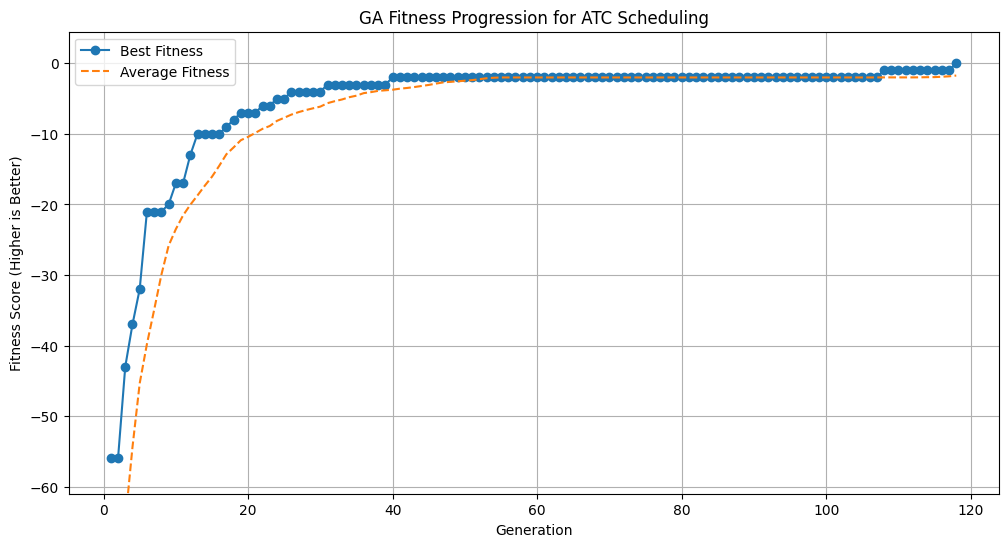

In [128]:
best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        days_per_week=DAYS_PER_WEEK,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
        crossover_rate=CROSSOVER_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)

# Q2 Exploring the Solution Space (5 points)

Now that you've written a base genetic algorithm, let's see what additional information you can learn about this problem. Every air traffic controller gets paid the same amount regardless of how many shifts they work. Management wants to find the minimum number of air traffic controllers they need without creating ANY constraint violations.

a. Using your genetic algorithm solver, find the minimum number of air traffic controllers needed.

b. Describe how you came up with your answer to part A and how confident you are in that answer.

# Solution 2

In [134]:
for num_people in reversed(range(7)):
    best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=num_people,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        days_per_week=DAYS_PER_WEEK,
        generations=1000,
        mutation_rate=MUTATION_RATE,
        crossover_rate=CROSSOVER_RATE,
    ) # CHECK THE PARAMETERS!!!

    # If there are no constrain violations
    possible = best_fitness == 0
    print(f'Problem is {'possible' if possible else 'likely impossible'} with {num_people} air traffic controllers ({best_fitness=})')
    if not possible: break

Problem is possible with 6 air traffic controllers (best_fitness=0)
Problem is possible with 5 air traffic controllers (best_fitness=0)
Problem is likely impossible with 4 air traffic controllers (best_fitness=-2)


I was able to find a solution with 4 air traffic controllers, but never anything lower.

# Q3 Tweaking the Parameters (10 points)

Now that you've written a base genetic algorithm, let's see if you can improve the performance by tweaking the parameters. Pick one of the GA Parameters and create a plot showing the results at different values.

In [152]:
from numpy import linspace

generations_sweep = []
best_fitness_sweep = []

mutation_rates = linspace(0, 0.1, 21)

for mutation_rate in mutation_rates:

    best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE, # parameter you could pick to sweep 
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        days_per_week=DAYS_PER_WEEK,
        generations=GENERATIONS,
        mutation_rate=mutation_rate, # parameter you could pick to sweep 
        crossover_rate=CROSSOVER_RATE, # parameter you could pick to sweep 
    )  # CHECK THE PARAMETERS!!!

    generations_sweep.append(len(history))
    best_fitness_sweep.append(best_fitness)

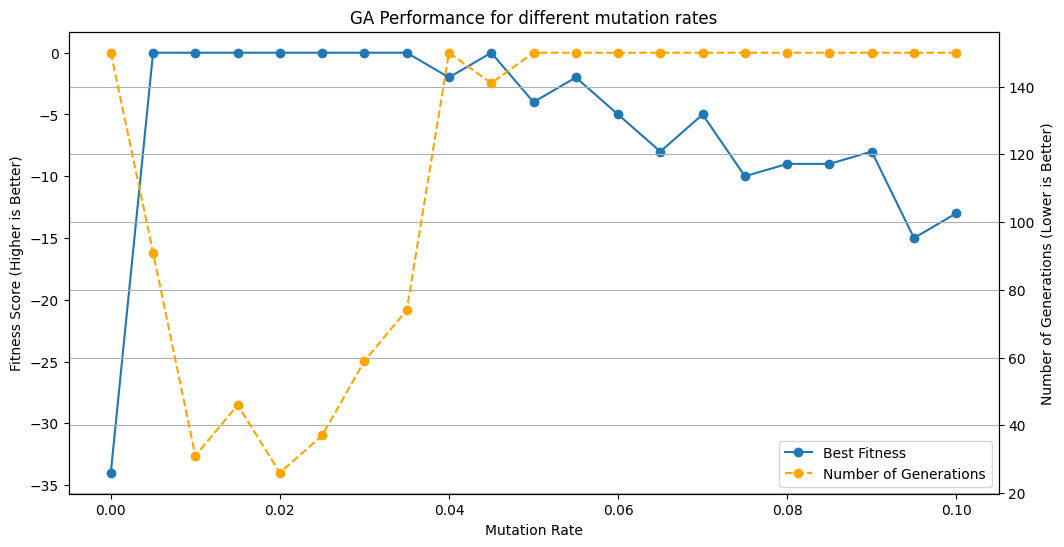

In [153]:
# CHANGE THIS CODE BELOW SO THAT IT PLOTS THE PARAMETER THAT GETS SWEEPED

fig = plt.figure(figsize=(12, 6))

ax1 = plt.gca()
p1, = ax1.plot(mutation_rates, best_fitness_sweep, marker='o', linestyle='-', label='Best Fitness')

ax2 = ax1.twinx()
p2, = ax2.plot(mutation_rates, generations_sweep, marker='o', linestyle='--', color='orange', label='Number of Generations')
ax2.set_ylabel('Number of Generations (Lower is Better)')

ax1.set_title('GA Performance for different mutation rates')
ax1.set_xlabel('Mutation Rate')
ax1.set_ylabel('Fitness Score (Higher is Better)')
ax1.legend(handles=[p1, p2], loc=4)

# Set y-limit to start slightly below the minimum fitness achieved or a reasonable lower bound
plt.grid(True)
plt.show()

### Interpret

- What parameter did you pick?

I picked to sweep mutation rate.

- What was optimal value for that parameter and why?

I found that the original value of 0.02 seems to be the optimal value. It was able to find an optimal result in the least number of generations.

- Is there another parameter do you think that tweaking it's value will improve the results and why?

Id be interested in looking at population size to see if a larger population would make it better. I would imagine that a higher population would almost never make the algorithm worse (as long as some other parametes were changed in tandem, like the number of individuals chosen for tournament selection), but I'm curious if the longer execution time would be worth it for the benefit.

## Q4 Changing Core Operations (15 points)

Finally, we are going to explore other methods for selection, crossover, and mutation. Choose your parent selection, mutation, crossover, or selection function and rewrite it to use a different method. Then, rerun the genetic algorithm and compare the results. Display the comparisons in a graph and interpret the results. You will do this twice; you can pick two different functions or pick the same function and come up with two different versions of it.

Completely optional, but if you are look for some inspiration this paper outlines the success of different kind of selection schemes: [A Comparative Analysis of Selection Schemes
Used in Genetic Algorithms](https://www.cse.unr.edu/~sushil/class/gas/papers/Select.pdf)

- Step/Method you are replacing: 

Parent Selection

- Step/Method you are replacing it with: 

A version of roulette wheel that uses softmax to create a probability distribution from random numbers

- Interpret the results of this replacement:

The algorithm seems to struggle to make small optimizations more. It gets very close quickly, but it can take dozens of generations just to fix a small penalty.


      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 000 010 000 010 010 100 010
ATC 2: 010 010 101 000 001 000 010
ATC 3: 100 001 000 101 000 001 000
ATC 4: 001 000 010 000 010 010 100
ATC 5: 010 100 010 010 100 010 001
----------------------------------------------------


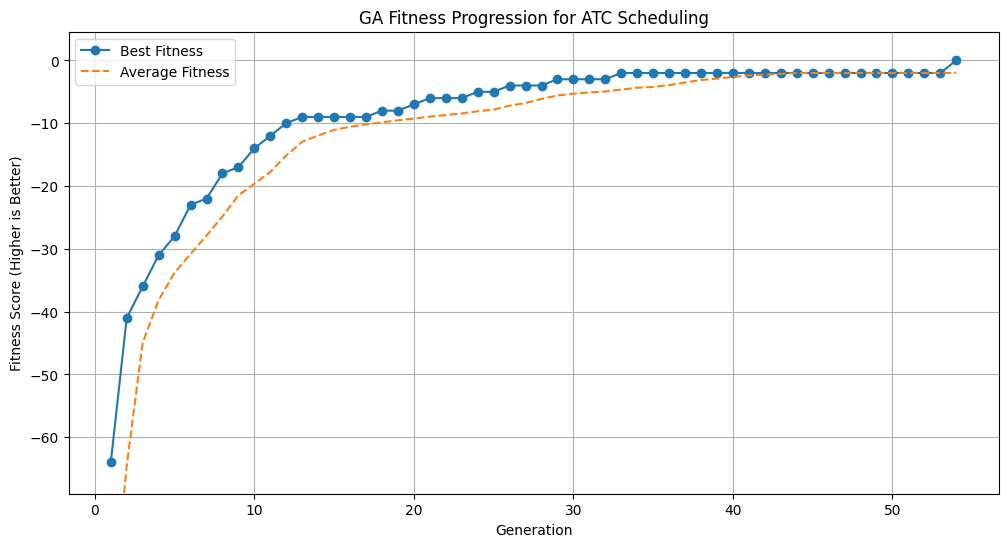

In [202]:
from math import exp
from numpy.random import choice

def softmax(numbers, temp=1.0):
    positive = [exp(number / temp) for number in numbers]
    total = sum(positive)
    return [number / total for number in positive]

def parent_selection_version_2(population, fitness_scores, temp = 1):
    """
    Uses softmax and random selection to select two parents from the population
    
    Args:
        population (list): The list of current individuals
        fitness_scores (list): The matching fitness scores for each individual
        temp (float): The temperature to use for SoftMax

    Returns:
        parent_1 (list): The chromosome of parent 1
        parent_2 (list): The chromosome of parent 2
    """
    # Choose the individuals in the tournament
    parent_indexes = choice(range(len(population)), 2, p=softmax(fitness_scores, temp=temp), replace=False)

    # Return the best two
    return population[parent_indexes[0]], population[parent_indexes[1]]

def genetic_algorithm_2(population_size, num_people, shifts_per_week, shifts_per_day, days_per_week,
                      generations, mutation_rate, crossover_rate):
    """
    Run the genetic algorithm! Finds an approximately optimal solution for the control tower staffing problem.

    Args:
        population_size (int): The number of individuals
        num_people (int): The number of people in the schedule.
        shifts_per_week (int): The number of shifts per week.
        shifts_per_day (int): The number of shifts per day
        generations (int): The number of generations to run
        mutation_rate (float): A number from 0-1 that represents how likely it is that an individual gene gets mutated.
        crossover_rate (float): A number from 0-1 that represents how likely it is that corssover happens

    Returns:
        best_schedule (list): The most fit chromosome that was found
        best_fitness (int): The score of the most fit chromasome
        history (list): The fitness of the most fit individual in each generation
        avg_history (list): The average fitness in each generation
    """
    history = []
    avg_history = []

    # Initialize population
    population = generate_population(population_size, num_people, shifts_per_week)

    for generation in range(generations):
        # Calculate fitness scores
        fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

        current_best_fitness = max(fitness_scores)
        history.append(current_best_fitness)
        avg_history.append(sum(fitness_scores) / len(fitness_scores))

        if current_best_fitness == 0:
            break

        # Create the new generation
        offspirng = []
        while len(offspirng) < population_size:
            # Select parents and create children with crossover
            parent_1, parent_2 = parent_selection_version_2(population, fitness_scores)
            child_1, child_2 = crossover(parent_1, parent_2, crossover_rate)

            # Mutate children
            child_1 = mutate(child_1, mutation_rate)
            child_2 = mutate(child_2, mutation_rate)

            offspirng += [child_1, child_2]

        # Calculate fitness scores of offspring
        offspirng_fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in offspirng]

        # Select the next generation
        population = select_survivors(population, fitness_scores, offspirng, offspirng_fitness_scores, population_size)

    # Calculate fitness scores one last time
    fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

    best_fitness = max(fitness_scores)
    best_schedule = population[fitness_scores.index(best_fitness)]

    return best_schedule, best_fitness, history, avg_history


# Copy code above to run and plot this function
best_schedule, best_fitness, history, avg_history = genetic_algorithm_2(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        days_per_week=DAYS_PER_WEEK,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
        crossover_rate=CROSSOVER_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)

- Step/Method you are replacing: 

Crossover

- Step/Method you are replacing it with:

Uniform crossover instead of one-point crossover

- Interpret the results of this replacement:

The results look fairly similar, although they may converge slightly more quickly.



      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 010 010 010 010 010 001 000
ATC 2: 000 010 101 000 101 000 100
ATC 3: 100 100 000 000 010 100 010
ATC 4: 001 000 010 010 000 010 010
ATC 5: 010 001 000 101 000 010 001
----------------------------------------------------


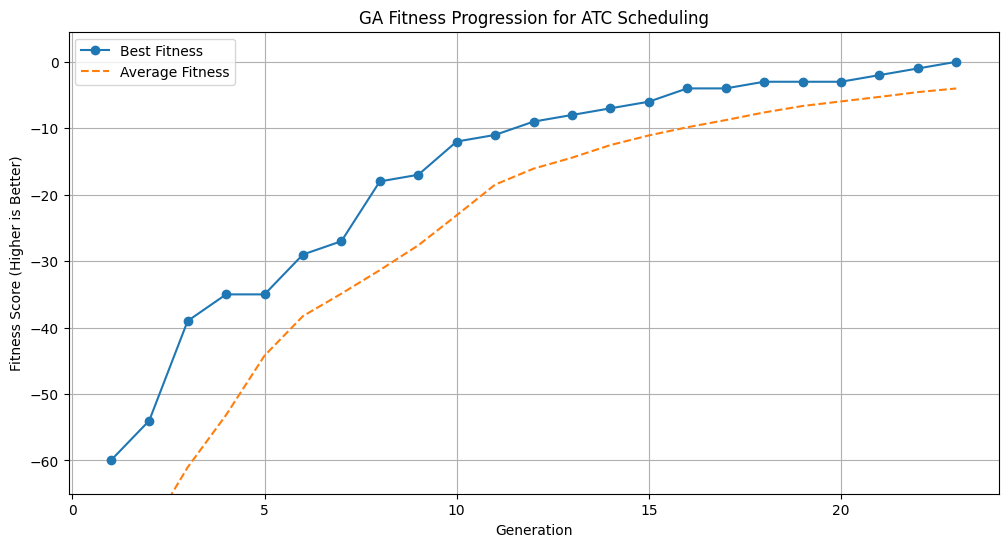

In [216]:
def crossover_verison_2(parent_1, parent_2, crossover_rate):
    """
    Uses uniform crossover to combine two parents into two children. Only switches person schedules, not
    
    Args:
        parent_1 (list): The schedule (a list of lists) of parent 1
        parent_2 (list): The schedule (a list of lists) of parent 2
        crossover_rate (float): A number from 0-1 that represents how likely it is that corssover happens

    Returns:
        child_1 (list): The schedule (a list of lists) of child 1
        child_2 (list): The schedule (a list of lists) of child 2
    """

    # If crossover doesn't happen, just return the parents
    if random.random() >= crossover_rate:
        return parent_1, parent_2

    # Initialize the children
    child_1 = []
    child_2 = []

    # For each person, either keep the schedules the same or swap them between two people.
    for day in range(len(parent_1)):
        if random.random() >= 0.5:
            child_1.append(parent_1[day])
            child_2.append(parent_2[day])
        else:
            child_1.append(parent_2[day])
            child_2.append(parent_1[day])

    return child_1, child_2

def genetic_algorithm_3(population_size, num_people, shifts_per_week, shifts_per_day, days_per_week,
                      generations, mutation_rate, crossover_rate):
    """
    Run the genetic algorithm! Finds an approximately optimal solution for the control tower staffing problem.

    Args:
        population_size (int): The number of individuals
        num_people (int): The number of people in the schedule.
        shifts_per_week (int): The number of shifts per week.
        shifts_per_day (int): The number of shifts per day
        generations (int): The number of generations to run
        mutation_rate (float): A number from 0-1 that represents how likely it is that an individual gene gets mutated.
        crossover_rate (float): A number from 0-1 that represents how likely it is that corssover happens

    Returns:
        best_schedule (list): The most fit chromosome that was found
        best_fitness (int): The score of the most fit chromasome
        history (list): The fitness of the most fit individual in each generation
        avg_history (list): The average fitness in each generation
    """
    history = []
    avg_history = []

    # Initialize population
    population = generate_population(population_size, num_people, shifts_per_week)

    for generation in range(generations):
        # Calculate fitness scores
        fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

        current_best_fitness = max(fitness_scores)
        history.append(current_best_fitness)
        avg_history.append(sum(fitness_scores) / len(fitness_scores))

        if current_best_fitness == 0:
            break

        # Create the new generation
        offspirng = []
        while len(offspirng) < population_size:
            # Select parents and create children with crossover
            parent_1, parent_2 = parent_selection(population, fitness_scores)
            child_1, child_2 = crossover_verison_2(parent_1, parent_2, crossover_rate)

            # Mutate children
            child_1 = mutate(child_1, mutation_rate)
            child_2 = mutate(child_2, mutation_rate)

            offspirng += [child_1, child_2]

        # Calculate fitness scores of offspring
        offspirng_fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in offspirng]

        # Select the next generation
        population = select_survivors(population, fitness_scores, offspirng, offspirng_fitness_scores, population_size)

    # Calculate fitness scores one last time
    fitness_scores = [evaluate_fitness(individual, num_people, shifts_per_week, shifts_per_day) for individual in population]

    best_fitness = max(fitness_scores)
    best_schedule = population[fitness_scores.index(best_fitness)]

    return best_schedule, best_fitness, history, avg_history


# Copy code above to run and plot this function
best_schedule, best_fitness, history, avg_history = genetic_algorithm_3(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        days_per_week=DAYS_PER_WEEK,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
        crossover_rate=CROSSOVER_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)